# 07 — Ringkasan Project & Demonstrasi Pipeline Big Cap

**Phase 7/7 — Ringkasan portfolio.** Notebook ini punya dua tugas:
1. **Merangkum temuan Phase 1–6** dalam enam grafik terpenting. Semua dibaca dari `reports/` dan `data/processed/`, tanpa estimasi baru.
2. **Menjalankan ulang pipeline untuk lima saham big cap** (BBCA, BBRI, TLKM, PTBA, ASII) lewat target configurable. Ini membuktikan bahwa kode benar-benar generik: seri Core, aturan, periode, dan aturan OOS **sama** dengan IHSG, dan tidak ada seleksi ulang.

Untuk saham berlaku aturan dividen besar (README poin 9): return ex-date dengan dividen > 10% harga sebelumnya dijadikan NaN. Versi tanpa aturan ini ditampilkan sebagai sensitivitas.

Semua hasil big cap bersifat **deskriptif dan bukan rekomendasi saham**. Uji OOS volatilitas mengikuti aturan Phase 6.

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import analysis as an
from src import bigcap as bc
from src import leadlag as ll
from src import plots
from src import regime as rg
from src.config import PROJECT_ROOT, load_config, output_dir, series_table, target_ticker
from src.data_loader import load_actions, load_prices

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

cfg = load_config()
series = series_table(cfg, groups=("target", "core", "tools"))
names = dict(zip(series["id"], series["name"]))
target_id = cfg["project"]["target_id"]
rep = lambda *p: PROJECT_ROOT.joinpath("reports", *p)   # noqa: E731
proc = output_dir(cfg, "data/processed")
prices_jkse = pd.read_parquet(proc / "prices_clean.parquet")
panel_end = prices_jkse.index.max()
print(f"Data IHSG s/d {panel_end:%d %b %Y}")

Data IHSG s/d 21 Oct 2026


## Bagian 1 — Temuan utama Phase 1–6 dalam enam grafik

### 1. Seri mana yang paling terkait dengan IHSG? (Phase 3)
Singapura, EM, dan Malaysia paling kuat (mingguan ±0,53), dan urutannya cukup stabil antar-periode. Rupiah berkorelasi negatif (−0,34). Semua angka di sini adalah asosiasi, bukan sebab-akibat.

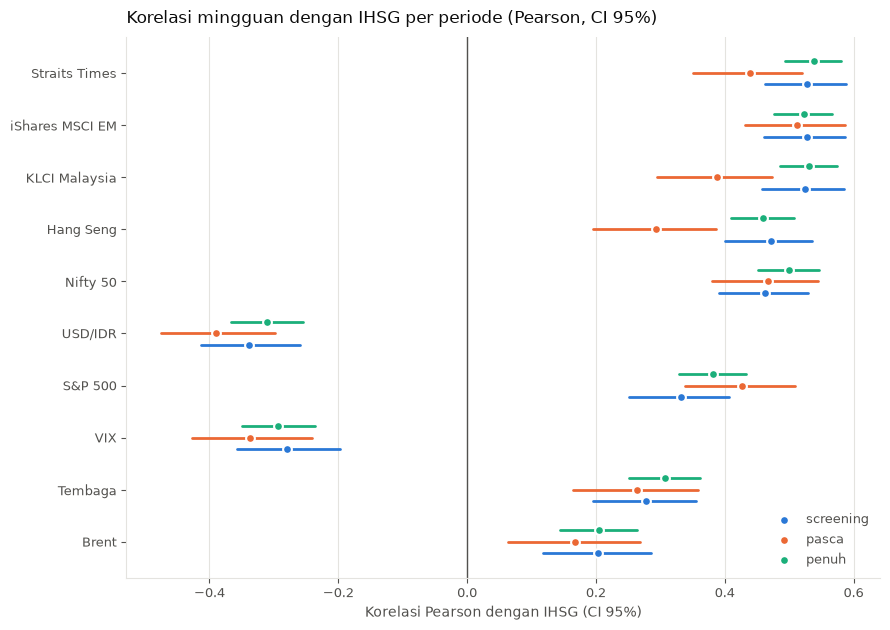

In [2]:
kor = pd.read_csv(rep("phase3", "korelasi.csv"))
wk = kor[(kor["frekuensi"] == "mingguan") & (kor["metode"] == "pearson")]
fig = plots.plot_corr_by_period(wk, names, "Korelasi mingguan dengan IHSG per periode (Pearson, CI 95%)")

### 2. Kapan pengaruhnya muncul? (Phase 4, in-sample 2010–2019)
Pasar yang tutup bersamaan dengan IHSG (STI, KLCI, HSI) berkorelasi di hari yang sama (k = 0). EEM, S&P 500, dan VIX yang tutup di New York baru terlihat di IHSG **hari berikutnya** (k = +1). Rupiah justru *mengikuti* IHSG (k = −1).

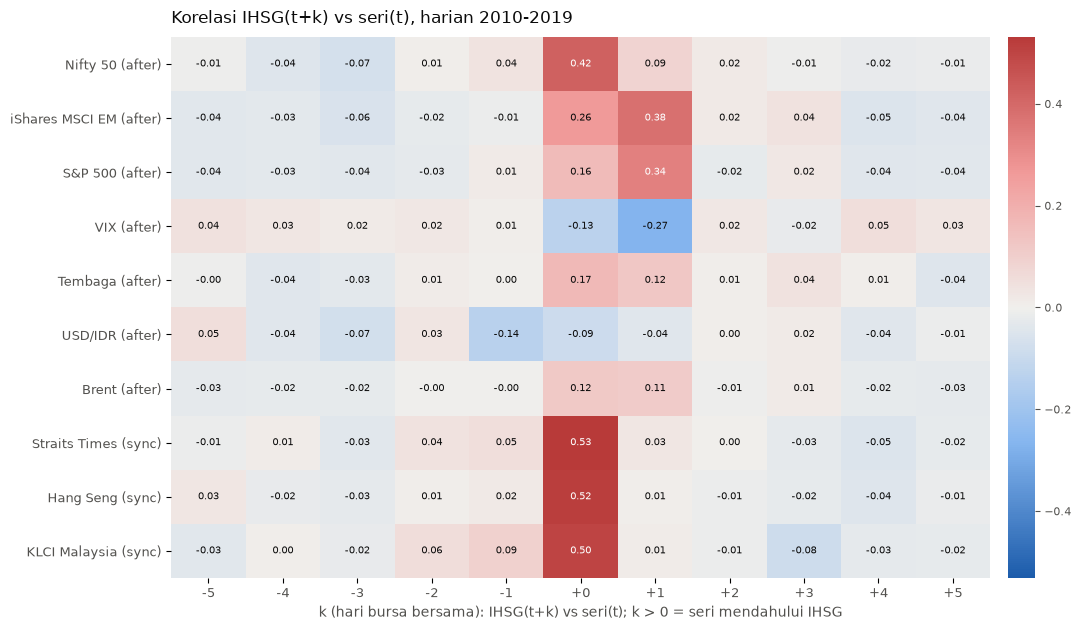

In [3]:
ccf = pd.read_csv(rep("phase4", "ccf.csv"))
sessions = dict(zip(series["id"], series["session"]))
fig = plots.plot_ccf_heatmap(ccf, names, sessions, "Korelasi IHSG(t+k) vs seri(t), harian 2010-2019")

### 3. Apakah keterkaitan berubah? (Phase 5)
Turunnya korelasi Hang Seng setelah 2023 adalah **tren** yang bertahan. Naiknya korelasi S&P 500 di 2020–2022 hanya **lonjakan sesaat** era COVID.

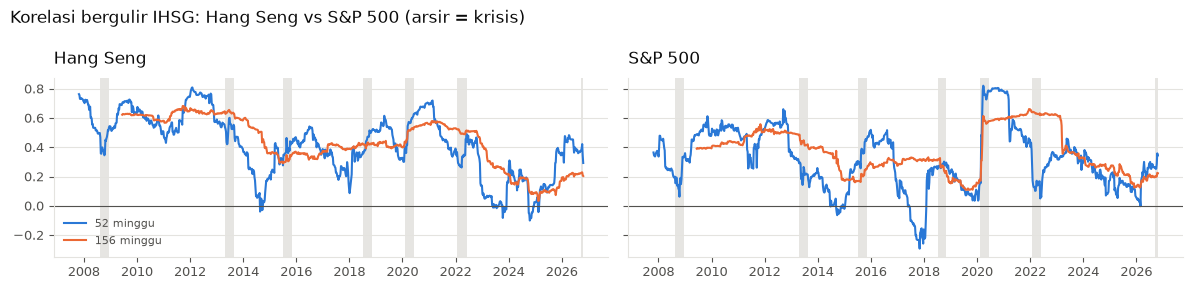

In [4]:
r52 = pd.read_csv(rep("phase5", "rolling_52.csv"), index_col=0, parse_dates=True)
r156 = pd.read_csv(rep("phase5", "rolling_156.csv"), index_col=0, parse_dates=True)
td = prices_jkse[target_id].dropna().index
rcfg = cfg["regime"]
wins = {k: rg.episode_window(td, a, tuple(rcfg["window_days"])) for k, a in (rcfg["episodes"] | rcfg["descriptive_only"]).items()}
fig = plots.plot_rolling_corr({52: r52[["HSI", "SPX"]], 156: r156[["HSI", "SPX"]]}, names,
                              [(w.start, w.end) for w in wins.values()], "Korelasi bergulir IHSG: Hang Seng vs S&P 500 (arsir = krisis)")

### 4. Seberapa dalam IHSG jatuh saat krisis? (Phase 5)
Median enam episode: IHSG −18% (drawdown), lebih dalam dari STI (−14%) dan KLCI (−10%), hampir sedalam EEM (−20%). Okt 2026 tampak spesifik Indonesia dan hanya deskriptif.

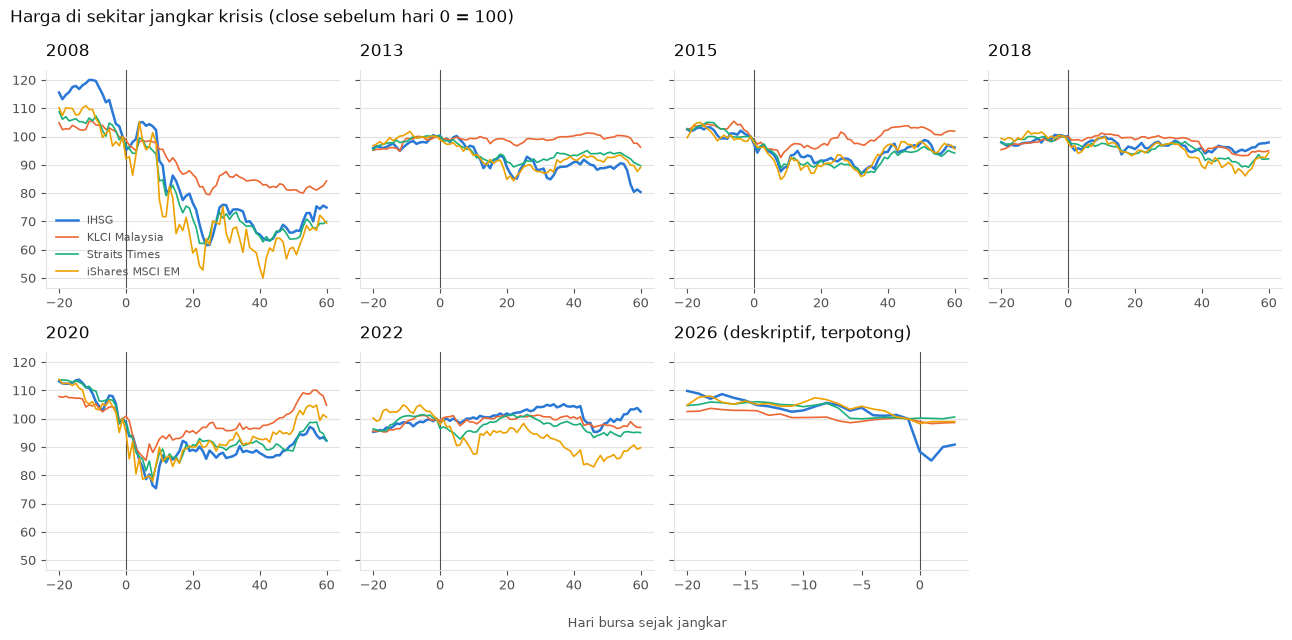

In [5]:
flags = pd.read_parquet(proc / "stale_quote_flags.parquet")
close = ll.drop_flagged(prices_jkse, flags)
paths = {k: rg.event_paths(close, [target_id] + rcfg["event_ids"], w, td) for k, w in wins.items()}
fig = plots.plot_event_paths(paths, names, "Harga di sekitar jangkar krisis (close sebelum hari 0 = 100)",
                             notes={k: "deskriptif, terpotong" for k in rcfg["descriptive_only"]})

### 5. Bisakah arah IHSG besok ditebak? (Phase 6, OOS 2020–2026)
**Vonis uji yang dikunci: tidak terbukti** (Diebold–Mariano log loss, p = 0,77). Model menangkap arah (hit rate 58,7% vs 51,9%), tetapi terlalu yakin di hari ekstrem, seperti terlihat di kalibrasi kelompok teratas. Volatilitas berbeda: **VIX terbukti membantu** prediksi volatilitas IHSG (GARCH-X p = 0,016; HAR-X p = 0,014).

,dengan_vix,tanpa_vix,n,selisih_loss_rata,dm_hln,p,p_satu_sisi_model_lebih_baik
loss,,,,,,,
QLIKE,1.0031,1.0391,1638,-0.0360,-2.4072,0.0162,0.0081
MSE,31.2216,31.9461,1638,-0.7245,-2.1223,0.0340,0.0170


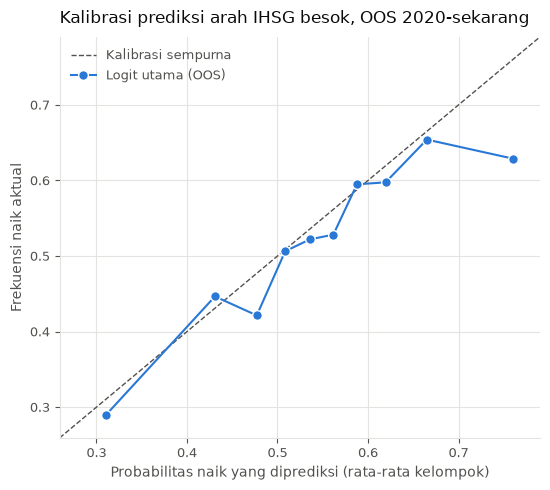

In [6]:
cal = pd.read_csv(rep("phase6", "arah_kalibrasi_utama.csv"), index_col=0)
fig = plots.plot_calibration({"Logit utama (OOS)": cal}, "Kalibrasi prediksi arah IHSG besok, OOS 2020-sekarang")
display(pd.read_csv(rep("phase6", "vol_garch_vs_garchx.csv"), index_col=0).round(4))

## Bagian 2 — Pipeline untuk lima saham big cap

Untuk tiap saham: `load_config(target_id=...)` → Phase 1 (data quality) → Phase 2 (cleaning + aturan dividen besar) → analisis A2–A6. Output tiap saham ada di `reports/targets/<id>/`. Data memakai cache yang sama dengan IHSG dan dipotong di tanggal akhir panel IHSG.

In [7]:
rows, rows_sens, details, p1_status, div_lists = [], [], {}, {}, {}
for tid in cfg["bigcap"]["targets"]:
    c = load_config(target_id=tid)
    tab = series_table(c)
    tk = target_ticker(c)
    prices = {k: v.loc[:panel_end] for k, v in load_prices(tab["ticker"].tolist(), start=c["project"]["start_date"],
                                                         verbose=False).items()}
    actions = load_actions([tk], start=c["project"]["start_date"])[tk].loc[:panel_end]
    p1 = bc.run_phase1(c, prices)
    p2 = bc.run_phase2(c, prices, actions, p1["start"]["start_used"])
    panel = bc.stock_panel(p2["clean"], p2["flags"], prices_jkse[target_id], c["project"]["primary_target"])
    res = bc.stock_analysis(c, panel, p2["div_days"], use_div_rule=True)
    sens = bc.stock_analysis(c, panel, p2["div_days"], use_div_rule=False)
    rows.append(res["row"]); rows_sens.append(sens["row"]); details[tid] = res
    qt = p1["quality"].set_index("id").loc[tid]
    p1_status[tid] = {"mulai": p1["start"]["start_used"], "status_kualitas": qt["status"], "pct_return_nol": round(qt["pct_zero"], 1),
                      "return_mode": p1["open"]["mode"], "baris_libur_dibuang": int(((p2["log"]["id"] == tid) & ~p2["log"]["reason"].str.contains("dividen")).sum()),
                      "di_antaranya_saat_IHSG_buka": int(p2["log"].loc[(p2["log"]["id"] == tid) & ~p2["log"]["reason"].str.contains("dividen"), "Date"]
                                                        .isin(prices_jkse[target_id].dropna().index).sum())}
    div_lists[tid] = p2["div_days"].assign(rasio=lambda d: d["rasio"].round(3))
    names[tid] = c["target"][0]["name"]
    print(f"{tid}: selesai | dividen besar: {len(p2['div_days'])} hari")
pd.DataFrame(p1_status).T

BBCA: selesai | dividen besar: 0 hari


BBRI: selesai | dividen besar: 0 hari


TLKM: selesai | dividen besar: 0 hari


PTBA: selesai | dividen besar: 5 hari


ASII: selesai | dividen besar: 0 hari


,mulai,status_kualitas,pct_return_nol,return_mode,baris_libur_dibuang,di_antaranya_saat_IHSG_buka
BBCA,2007-01-01 00:00:00,OK,13.0,close_to_close,84,23
BBRI,2007-01-01 00:00:00,OK,11.5,close_to_close,84,23
TLKM,2007-01-01 00:00:00,OK,12.1,close_to_close,82,21
PTBA,2007-01-01 00:00:00,OK,10.0,close_to_close,84,23
ASII,2007-01-01 00:00:00,OK,10.9,close_to_close,85,24


In [8]:
print("Hari ex-date dividen besar (> 10% close sebelumnya) yang returnnya dijadikan NaN:")
pd.concat(div_lists, names=["saham"]).round(2) if any(len(v) for v in div_lists.values()) else print("tidak ada")

Hari ex-date dividen besar (> 10% close sebelumnya) yang returnnya dijadikan NaN:


dividen  close_sebelumnya  rasio
saham Date                                        
PTBA  2020-06-19   326.46            2450.0   0.13
      2022-06-06   688.52            4630.0   0.15
      2023-06-26  1094.05            3700.0   0.30
      2024-05-21   397.71            2930.0   0.14
      2025-06-23   332.44            2950.0   0.11

### Tabel perbandingan

- **Beta:** mingguan, HAC, satu faktor (IHSG, USD/IDR, EEM masing-masing terpisah), untuk 2010–2019 dan 2020+.
- **Asimetri:** korelasi saham–EEM di minggu EEM turun vs naik, dikurangi selisih yang diharapkan di bawah normal (CI bootstrap).
- **Lead:** return saham besok ~ EEM dan Δpremium EIDO malam ini, in-sample 2010–2019.
- **Krisis:** median enam episode.
- **GARCH-X:** γ in-sample 2010–2019 (uji LR γ = 0) dan uji OOS 2020+ dengan DM QLIKE, seperti Phase 6.

In [9]:
table, champs = bc.comparison_table(rows)
show = ["beta_ihsg_2010_2019", "beta_ihsg_2020+", "beta_usdidr_2010_2019", "beta_usdidr_2020+", "beta_eem_2010_2019",
        "beta_eem_2020+", "r_turun_eem", "r_naik_eem", "asimetri_berlebih", "asimetri_ci_lo", "asimetri_ci_hi",
        "lead_beta_eem", "lead_tambahan_r2_dpremium", "lead_p_dpremium", "krisis_drawdown_median", "krisis_return60_median",
        "garch_gamma_is", "garch_lr_p_is", "garch_dm_qlike_p", "garch_dm_qlike_selisih"]
display(table[show].round(3).T)
champs.assign(saham=champs["saham"].map(lambda i: f"{i} ({names[i]})"))

id,BBCA,BBRI,TLKM,PTBA,ASII
beta_ihsg_2010_2019,1.048,1.474,0.747,1.200,1.423
beta_ihsg_2020+,0.872,1.154,1.051,0.780,1.004
beta_usdidr_2010_2019,-0.785,-1.302,-0.371,-0.846,-1.201
beta_usdidr_2020+,-0.825,-1.172,-1.190,-0.811,-1.153
beta_eem_2010_2019,0.422,0.625,0.249,0.660,0.543
beta_eem_2020+,0.520,0.616,0.363,0.298,0.586
r_turun_eem,0.331,0.369,0.258,0.229,0.417
r_naik_eem,0.266,0.250,0.036,0.217,0.245
asimetri_berlebih,0.071,0.127,0.227,0.017,0.179
asimetri_ci_lo,-0.077,-0.009,0.069,-0.130,-0.015


,saham,nilai
"paling sensitif ke rupiah (beta USD/IDR paling negatif, 2010-2019)",BBRI (Bank Rakyat Indonesia),-1.302417
"paling sensitif ke EM (beta EEM terbesar, 2010-2019)",PTBA (Bukit Asam),0.6598
paling asimetris vs EEM (asimetri berlebih terbesar),TLKM (Telkom Indonesia),0.226996
paling dalam saat krisis (median drawdown),PTBA (Bukit Asam),-0.325618
paling responsif ke VIX (gamma GARCH-X in-sample),PTBA (Bukit Asam),1.199787


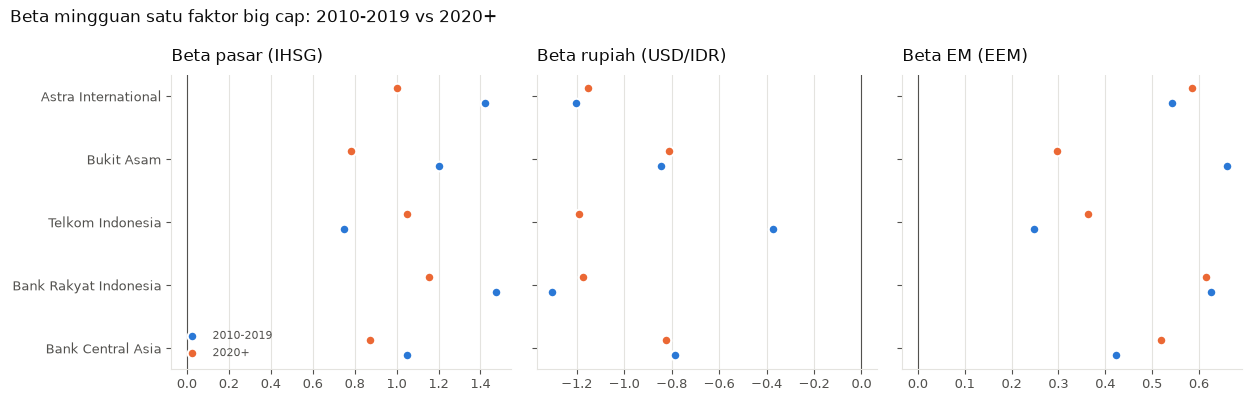

In [10]:
fig = plots.plot_bigcap_betas(table, {"Beta pasar (IHSG)": ("beta_ihsg_2010_2019", "beta_ihsg_2020+"),
                                      "Beta rupiah (USD/IDR)": ("beta_usdidr_2010_2019", "beta_usdidr_2020+"),
                                      "Beta EM (EEM)": ("beta_eem_2010_2019", "beta_eem_2020+")},
                             names, "Beta mingguan satu faktor big cap: 2010-2019 vs 2020+")

### Sensitivitas: tanpa aturan dividen besar

In [11]:
table_s, champs_s = bc.comparison_table(rows_sens)
key = ["beta_ihsg_2010_2019", "beta_ihsg_2020+", "beta_usdidr_2020+", "beta_eem_2020+", "asimetri_berlebih",
       "garch_gamma_is", "garch_dm_qlike_p"]   # semua dividen besar jatuh di 2020+, jadi 2010-2019 tidak terpengaruh
delta = (table_s[key] - table[key]).round(4)
display(pd.concat({"dengan aturan": table[key], "tanpa aturan": table_s[key], "selisih": delta}, axis=1).round(3))
print("Juara berubah tanpa aturan?", bool((champs_s["saham"] != champs["saham"]).any()))

dengan aturan                                                                                                           tanpa aturan                                                                     \
     beta_ihsg_2010_2019 beta_ihsg_2020+ beta_usdidr_2020+ beta_eem_2020+ asimetri_berlebih garch_gamma_is garch_dm_qlike_p beta_ihsg_2010_2019 beta_ihsg_2020+ beta_usdidr_2020+ beta_eem_2020+ asimetri_berlebih   
id                                                                                                                                                                                                                   
BBCA               1.048           0.872            -0.825          0.520             0.071          0.884            0.222               1.048           0.872            -0.825          0.520             0.071   
BBRI               1.474           1.154            -1.172          0.616             0.127          0.628            0.099               1.474           1.154            -1.172          0.616             0.127   
TLKM               0.747           1.051            -1.190          0.363             0.227          0.409            0.208               0.747           1.051            -1.190          0.363             0.227   
PTBA               1.200           0.780            -0.811          0.298             0.017          1.200            0.183               1.200           0.784            -0.824          0.285             0.023   
ASII               1.423           1.004            -1.153          0.586             0.179          0.745            0.126               1.423           1.004            -1.153          0.586             0.179   

                                                 selisih                                                                                                     
     garch_gamma_is garch_dm_qlike_p beta_ihsg_2010_2019 beta_ihsg_2020+ beta_usdidr_2020+ beta_eem_2020+ asimetri_berlebih garch_gamma_is garch_dm_qlike_p  
id                                                                                                                                                           
BBCA          0.884            0.222                 0.0           0.000             0.000          0.000             0.000            0.0            0.000  
BBRI          0.628            0.099                 0.0           0.000             0.000          0.000             0.000            0.0            0.000  
TLKM          0.409            0.208                 0.0           0.000             0.000          0.000             0.000            0.0            0.000  
PTBA          1.200            0.211                 0.0           0.003            -0.014         -0.013             0.006            0.0            0.028  
ASII          0.745            0.126                 0.0           0.000             0.000          0.000             0.000            0.0            0.000

Juara berubah tanpa aturan? False


### Simpan hasil

Disimpan ke `reports/phase7/`, plus detail per saham di `reports/targets/<id>/phase7/`.

In [12]:
tables = {"bigcap_perbandingan": table, "bigcap_juara": champs, "bigcap_perbandingan_tanpa_aturan_dividen": table_s,
          "bigcap_juara_tanpa_aturan_dividen": champs_s, "bigcap_status_phase1": pd.DataFrame(p1_status).T}
paths = an.save_tables(rep("phase7"), tables, {"targets": cfg["bigcap"]["targets"], "data_sampai": panel_end})
for tid, res in details.items():
    an.save_tables(output_dir(load_config(target_id=tid), "reports", "phase7"),
                   {"beta": res["betas"], "asimetris_eem": res["asym"], "lead_koefisien": res["lead_coef"],
                    "lead_model": res["lead_models"], "event_study": res["event_study"]}, {"garch": res["garch"]})
[p.name for p in paths]

['bigcap_perbandingan.csv',
 'bigcap_juara.csv',
 'bigcap_perbandingan_tanpa_aturan_dividen.csv',
 'bigcap_juara_tanpa_aturan_dividen.csv',
 'bigcap_status_phase1.csv',
 'summary.json']

## Ringkasan insight

Semua angka big cap bersifat deskriptif, kecuali uji OOS volatilitas yang mengikuti aturan Phase 6. **Bukan rekomendasi saham.**

In [13]:
display(Markdown(bc.bigcap_summary(table, champs, names)))

### Ringkasan big cap (demonstrasi pipeline; deskriptif, bukan rekomendasi)

- **paling sensitif ke rupiah (beta USD/IDR paling negatif, 2010-2019):** Bank Rakyat Indonesia (-1.302).
- **paling sensitif ke EM (beta EEM terbesar, 2010-2019):** Bukit Asam (+0.660).
- **paling asimetris vs EEM (asimetri berlebih terbesar):** Telkom Indonesia (+0.227).
- **paling dalam saat krisis (median drawdown):** Bukit Asam (-0.326).
- **paling responsif ke VIX (gamma GARCH-X in-sample):** Bukit Asam (+1.200).
- **VIX membantu prediksi volatilitas OOS (DM QLIKE, α 5%):** tidak ada dari 5 saham.
- **Δpremium EIDO menambah daya jelas lead di atas EEM (in-sample 2010-2019):** Bank Central Asia, Bank Rakyat Indonesia, Telkom Indonesia, Astra International.